## 1. Linear Regression: the model

A line is defined by its slope and intercept:

$$y = mx + b$$

- $m$ = slope (change in $y$ per one unit of $x$)
- $b$ = intercept (value of $y$ when $x = 0$)

Codecademy uses $m, b$. In statistics notation: $y = \beta_0 + \beta_1 x + \varepsilon$

**Goal:** find the "best" $m$ and $b$. In OLS (ordinary least squares), "best" means minimising the sum of squared errors:

$$\min_{m,b} \sum_{i=1}^{n} (y_i - (mx_i + b))^2$$

Closed-form solution:

$$m = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2} \qquad b = \bar{y} - m\bar{x}$$

R equivalent: `lm(revenue ~ months)`

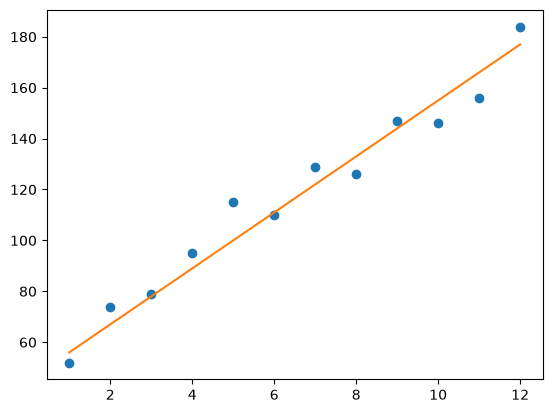

In [1]:
import matplotlib.pyplot as plt

months = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
revenue = [52, 74, 79, 95, 115, 110, 129, 126, 147, 146, 156, 184]

# Guessed line (by eye)
m = 11   # slope
b = 45   # intercept

y = [i * m + b for i in months]   # y = mx + b for each month

plt.plot(months, revenue, "o")   # data points
plt.plot(months, y)              # guessed line
plt.show()

# For comparison, the OLS fit is m ≈ 10.4, b ≈ 50.2

## 2. Loss

Loss = how badly the line predicts the data. For OLS it's the sum of squared errors (SSE):

$$\text{SSE} = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

The errors are squared so that points above and below the line count the same, and so that big misses are penalised more. The line with lower SSE fits better.

In [2]:
x = [1, 2, 3]
y = [5, 1, 3]

m1, b1 = 1, 0      # line 1: y = x
m2, b2 = 0.5, 1    # line 2: y = 0.5x + 1

y_predicted1 = [i * m1 + b1 for i in x]
y_predicted2 = [i * m2 + b2 for i in x]

total_loss1 = 0
for i in range(len(y)):
    total_loss1 += (y[i] - y_predicted1[i]) ** 2

total_loss2 = 0
for i in range(len(y)):
    total_loss2 += (y[i] - y_predicted2[i]) ** 2

print(total_loss1, total_loss2)
# 17 13.5

better_fit = 2   # line 2 has the lower loss

# Shorter alternatives:
total_loss1 = sum((a - p) ** 2 for a, p in zip(y, y_predicted1))   # zip pairs up actual and predicted values element by element

import numpy as np
total_loss1 = np.sum((np.array(y) - np.array(y_predicted1)) ** 2)   # vectorised: subtracts whole arrays at once, no loop

17 13.5


## 3. Gradient Descent: intercept

Gradient descent: move each parameter in the direction that lowers the loss, step by step, until the loss stops decreasing (the bottom of the "hill").

Loss used from here on is the MSE:

$$\text{MSE} = \frac{1}{N}\sum_{i=1}^{N} (y_i - (mx_i + b))^2$$

Its partial derivative with respect to $b$:

$$\frac{\partial\,\text{MSE}}{\partial b} = -\frac{2}{N}\sum_{i=1}^{N} (y_i - (mx_i + b))$$

- Gradient < 0: loss falls as $b$ increases, so increase $b$
- Gradient > 0: decrease $b$

In [3]:
def get_gradient_at_b(x, y, m, b):
    diff = 0
    for i in range(0, len(x)):
        x_val = x[i]
        y_val = y[i]
        diff += (y_val - ((m * x_val) + b))   # sum of residuals
    b_gradient = (-2 / len(x)) * diff
    return b_gradient

# Shorter alternative (NumPy, no loop):
import numpy as np

def get_gradient_at_b_np(x, y, m, b):
    x, y = np.array(x), np.array(y)               # lists to arrays, so maths works element-wise
    return -2 / len(x) * np.sum(y - (m * x + b))

## 4. Gradient Descent: slope

Partial derivative of the MSE with respect to $m$:

$$\frac{\partial\,\text{MSE}}{\partial m} = -\frac{2}{N}\sum_{i=1}^{N} x_i\,(y_i - (mx_i + b))$$

Same as the $b$ gradient, but each residual is weighted by its $x_i$ (chain rule: $\partial(mx_i)/\partial m = x_i$).

In [4]:
def get_gradient_at_m(x, y, m, b):
    diff = 0
    N = len(x)
    for i in range(N):
        y_val = y[i]
        x_val = x[i]
        diff += x_val * (y_val - ((m * x_val) + b))   # residual weighted by x
    m_gradient = (-2 / N) * diff
    return m_gradient

# Shorter alternative (NumPy):
def get_gradient_at_m_np(x, y, m, b):
    x, y = np.array(x), np.array(y)
    return -2 / len(x) * np.sum(x * (y - (m * x + b)))

## 5. One gradient descent step

Update rule: move each parameter against its gradient, scaled by the learning rate $\alpha$:

$$b_{new} = b - \alpha \frac{\partial\,\text{MSE}}{\partial b} \qquad m_{new} = m - \alpha \frac{\partial\,\text{MSE}}{\partial m}$$

- Minus sign: the gradient points uphill, so we step the opposite way
- $\alpha$ too large: overshoots the minimum. $\alpha$ too small: very slow.

Structure, where each layer only uses the one below it:
1. `get_gradient_at_b` / `get_gradient_at_m`: which way is downhill, and how steep?
2. `step_gradient`: asks both gradients, then moves $b$ and $m$ one small step downhill
3. Loop (next section): calls `step_gradient` many times until reaching the bottom

⚠️ Learning point: Codecademy switched the gradient functions to `(x, y, b, m)` in this exercise, while sections 3–4 use `(x, y, m, b)`. Positional arguments in the wrong order silently swap $m$ and $b$, with no error. Use keyword arguments (`m=..., b=...`) when calling, so the order doesn't matter.

⚠️ Learning point: `step_gradient` returns new values but doesn't change `b` and `m` by itself. The result has to be caught: `b, m = step_gradient(...)`. This is unpacking, which assigns the returned list's items to the variables in order. Without it, `b` and `m` stay unchanged and the loop never moves.

In [5]:
def step_gradient(x, y, b_current, m_current):
    b_gradient = get_gradient_at_b(x, y, m=m_current, b=b_current)   # keywords: safe whatever the parameter order
    m_gradient = get_gradient_at_m(x, y, m=m_current, b=b_current)
    b = b_current - (0.01 * b_gradient)   # learning rate = 0.01
    m = m_current - (0.01 * m_gradient)
    return [b, m]

months = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
revenue = [52, 74, 79, 95, 115, 110, 129, 126, 147, 146, 156, 184]

b = 0   # starting intercept guess
m = 0   # starting slope guess

b, m = step_gradient(months, revenue, b, m)   # unpacking: 1st returned value -> b, 2nd -> m
print(b, m)
# 2.355 17.783333333333335
# One step from (0, 0) overshoots the slope (OLS: m ≈ 10.4). The loop in the next section corrects this.

# Without unpacking, the result is lost:
# step_gradient(months, revenue, b, m)   # returns [2.355, 17.78], but b and m stay 0

# R equivalent of unpacking:
# res <- step_gradient(months, revenue, b, m)
# b <- res[[1]]; m <- res[[2]]

2.355 17.78333333333333


## 6. Convergence and learning rate

**Convergence:** the point where the loss stops changing, or changes only negligibly, when the parameters are updated. At that point, $m$ and $b$ have settled at (hopefully) their best values.

Stopping rule, in practice: stop when the improvement in loss falls below a small tolerance $\varepsilon$:

$$|\,\text{MSE}_{t} - \text{MSE}_{t-1}\,| < \varepsilon$$

**Learning rate $\alpha$** sets the step size down the loss curve:

| $\alpha$ | What happens |
|---|---|
| Too small (e.g. $10^{-9}$) | Parameters barely move, so it doesn't converge in the available iterations |
| Too large (e.g. $0.01$ here) | Overshoots the minimum, oscillates or explodes, so it **diverges** |
| Good enough | Converges efficiently. There's no need for the "best" $\alpha$. |

- "Too large" depends on the data scale: 0.01 worked in section 5's revenue example but diverges on this dataset
- For linear regression, MSE is convex (one bowl), so a well-chosen $\alpha$ converges to the global minimum

## 7. Gradient descent: the full loop

Repeat the step from section 5 `num_iterations` times, feeding each step's output into the next:

$$(b, m)_{t+1} = (b, m)_t - \alpha \,\nabla \text{MSE}\big((b, m)_t\big)$$

Structure, where each layer only uses the one below it:
1. `get_gradient_at_b` / `get_gradient_at_m`: which way is downhill?
2. `step_gradient`: one move downhill
3. `gradient_descent`: repeat the move many times

Result (α = 0.01, 1000 iterations): b ≈ 49.60, m ≈ 10.46. The OLS solution is b = 50.23, m = 10.39, so it's close but not fully converged. More iterations, or a larger α, would get there.

In [ ]:
# step_gradient updated: learning_rate is now a parameter instead of a hardcoded 0.01
# Codecademy's order changed again: (b, m, x, y, learning_rate)
def step_gradient(b_current, m_current, x, y, learning_rate):
    b_gradient = get_gradient_at_b(x, y, m=m_current, b=b_current)   # keywords: the notebook's gradient functions take (x, y, m, b)
    m_gradient = get_gradient_at_m(x, y, m=m_current, b=b_current)
    b = b_current - (learning_rate * b_gradient)
    m = m_current - (learning_rate * m_gradient)
    return [b, m]

def gradient_descent(x, y, learning_rate, num_iterations):
    b = 0   # initial guess
    m = 0
    for i in range(num_iterations):   # i is never used, the loop only counts (convention: `for _ in ...`)
        b, m = step_gradient(b, m, x, y, learning_rate)   # KEY LINE: catch the return so each step starts from the last one
    return b, m   # outside the loop, otherwise it returns after one step

b, m = gradient_descent(months, revenue, 0.01, 1000)
print(b, m)

y = [m*x + b for x in months]   # fitted line

plt.figure()
plt.plot(months, revenue, "o")
plt.plot(months, y)
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Gradient descent fit (α = 0.01, 1000 iterations)")
plt.savefig("charts/07_gradient_descent_fit.png", bbox_inches="tight")   # before show()
plt.show()

**Learning points**
- `b, m = step_gradient(...)` inside the loop is the crucial line. Without it, `b, m` stay 0 and every iteration repeats the same first step. This is the same "catch the return value" trap as in section 5.
- Codecademy's `step_gradient(b, m, x, y)` calls the gradient functions positionally. That would silently swap `b` and `m` against this notebook's `(x, y, m, b)` functions, so the calls use keywords.